# Rapid Lightning — an honest investigation of genetic-programming ensembles for tabular classification

**A novel method, a full compile-to-C toolchain, and a rigorous benchmark showing it does *not* beat tuned gradient-boosted trees — bar a marginal small-data residual.**

*A clean, scoped negative result. Every number below is produced by the benchmark in [`benchmarks/gp_vs_gbdt.py`](gp_vs_gbdt.py); nothing is hand-entered. Current as of June 2026.*

---

## Abstract

We explored whether a **genetic-programming (GP) ensemble** — which evolves small algebraic programs and combines them through a linear head, then compiles the whole model to a dependency-free C `.so` for tens-of-nanoseconds inference — can compete with gradient-boosted decision trees (GBDTs) on tabular classification. We tried two objectives: **v1**, where members are evolved as *predictors* (accuracy + AdaBoost-style boosting), and **v3 "head-aware"**, where members are evolved as *signal generators* for the linear head.

Across **16 OpenML datasets** with repeated stratified cross-validation and paired significance testing, against **properly tuned (early-stopped, regularized) GBDT baselines**, we find:

1. **No speed advantage** in the mean. A trained GBDT compiles to fast C just as well (treelite, m2cgen, lleaves); compiled-vs-compiled, a size-matched GBDT can be *faster* than the GP. *(The GP's one genuine structural edge is **latency determinism** — branchless code, ~10× lower input-dependent jitter than a branchy compiled tree — relevant only to hard-real-time / HFT-adjacent niches where worst-case latency dominates; see the Addendum.)*
2. **No accuracy advantage.** Neither GP variant *beats* a tuned GBDT stack on its own. Adding v1 to the stack yields a **small, significant complementary gain on a handful of small datasets** (e.g. +0.006 on diabetes, +0.015 on ionosphere) and nothing — or a negligible loss — on large ones; the mean gain across all 16 datasets is just **+0.002 AUC** (median +0.001); **v3 (head-aware) adds essentially nothing anywhere** (it even significantly *hurts* one set). An earlier, much larger v1 "win" (+0.03) was an **artifact of un-regularized baselines** and collapsed to non-significance under tuned ones. The surviving effect is real but practically marginal.
3. **The niche is already occupied.** As of 2026, the state of the art on exactly the small-tabular regime where our method showed its only flicker of signal is **tabular foundation models (TabPFN-2.5/3)**, which themselves *outperform* tuned GBDTs.

The methods are genuinely novel; their measured practical value over tuned GBDTs is approximately nil. We report this in full, because a clean, falsifiable negative — with the apparatus to reproduce it — is a contribution.

## 1 · The methods

**Genetic programming (GP)** evolves a population of small programs — here, expression trees over `{+, −, ×, min, max, <, …}` on the input features — under selection, crossover, and mutation [Koza, 1992]. Our ensemble evolves several such members and combines their outputs through a **logistic-regression head**. Two objectives were tried:

- **v1 — members as predictors.** Each member is rewarded for classification accuracy, with AdaBoost-style reweighting [Freund & Schapire, 1997] so later members focus on what earlier ones got wrong. The head then combines them.
- **v3 — "head-aware."** Members are rewarded *not* for predicting, but for adding a coordinate the linear head can use: maximize `corr(member_output ⟂ pool, residual)²` — functional gradient boosting in feature space. Individually the members are near-chance; together they feed the head. This was the method we initially believed was strongest.

Both compile, via straight-line code generation, to a small dependency-free C function — the deployment artifact this project was originally built around.

## 2 · The compile-to-C toolchain — and why it is **not** novel

Our toolchain ("XGForge") transcribes a trained tree/GP model to nested-`if`/straight-line C and compiles it with `gcc -O3` into a ~15 KB `.so` that predicts in tens of nanoseconds with no ML runtime. It is clean and fast in its niche (binary, dense, fp32, single-row) — but the **technique is well-established**, and we want to be explicit about that:

- **[Treelite](https://treelite.readthedocs.io/)** / **TL2cgen** (DMLC, since ~2017) — a model compiler for decision-tree ensembles that exports a stand-alone prediction library.
- **[m2cgen](https://github.com/BayesWitnesses/m2cgen)** — transpiles trained models to zero-dependency native code in 15+ languages including C.
- **[lleaves](https://siboehm.com/articles/21/lleaves)** — LLVM-compiled decision trees, ≥10× speedup, drop-in for LightGBM.
- **[Hummingbird](https://github.com/microsoft/hummingbird)** (Microsoft) — compiles trees to tensor computations.

So "tiny fast C from a trained model" is table stakes, available from mature, general, maintained tools. Our reimplementation is a niche micro-optimization, not a new capability.

## 3 · What is state-of-the-art for tabular data in 2026?

For most of the last decade, **gradient-boosted decision trees** (XGBoost [Chen & Guestrin, 2016], LightGBM [Ke et al., 2017], CatBoost) were the default winners on tabular data, and deep learning struggled to match them [Shwartz-Ziv & Armon, 2022; Grinsztajn et al., 2022].

That has shifted. **Tabular foundation models** now match or beat tuned GBDTs:

- **TabPFN v2** (Hollmann et al., *Nature*, 2025) — a transformer doing in-context learning, pre-trained on ~130M synthetic datasets, strongest on small data with no tuning.
- **[TabPFN-2.5](https://arxiv.org/abs/2511.08667)** (Nov 2025) — up to 50k rows / 2000 features; "substantially outperforms tuned tree-based models" and matches a 4-hour AutoGluon ensemble.
- **TabPFN-3** (May 2026) — up to ~1M rows.

This matters for our result: the **small-tabular regime is exactly where our GP showed its only (marginal) signal — and it is precisely where TabPFN dominates.** So the niche is doubly subsumed: not only do tuned GBDTs hold, the actual frontier has moved past them. (We could not run TabPFN here — it requires authenticated weight download — so we cite it rather than benchmark it.)

### The 2026 regime map — where each method actually fits

Tabular ML in 2026 isn't winner-take-all; it's regimes. Synthesizing the benchmark below with the methods' documented limits and practitioner reports:

| capability | TabPFN-2.5/3 | tuned GBDTs | Rapid Lightning (GP) |
|---|---|---|---|
| small data (<1k rows), no tuning | ★ best | good | ≈ GBDT (no better) |
| massive scale (10–100M+ rows) | ✗ caps ~1M rows (GPU KV-cache) | ★ out-of-core on CPU | ✗ `O(N)` training |
| high rows **and** high features | ✗ hard tradeoff (1M×200 · 100k×2k · 1k×20k) | ★ sparse / one-hot, no tradeoff | ✗ |
| custom business loss (asymmetric · LambdaMART · Tweedie) | ✗ frozen prior | ★ first-class | ✗ fixed logistic head |
| cheap-CPU / edge / real-time | ✗ needs GPU, ~10s–100s ms | ★ compile to tiny C (treelite/m2cgen) | ✓ tiny C, lowest latency jitter |

Read honestly: **tuned GBDTs win or tie almost every production regime** — scale, dimensionality, custom objectives, and cheap-CPU deployment-by-compilation. **TabPFN owns small-data prototyping** but is a GPU/server tool, *unsuited to robots, sensors, or flight hardware* (tens-of-ms forward pass, scores whole batches not single rows). And **Rapid Lightning's only cell a GBDT doesn't already cover is latency *determinism*** (the Addendum) — a profile property, not a quality one. **The edge belongs to compiled GBDTs; TabPFN's absence there does not promote the GP.**

*(CPU inference is a large, fast-growing target — the 2026 agentic-AI buildout is pushing the data-center CPU TAM up sharply and even causing a server-CPU crunch — but that lifts every compile-to-CPU method equally; it is not an advantage specific to this one.)*

## 4 · Benchmark methodology

We test the only claim worth testing: **does either GP variant add signal a *tuned* GBDT stack lacks?**

- **Datasets.** 16 OpenML binary-classification datasets spanning ~350–6000 rows (capped at 6000; GP training is `O(N)`). Numeric features standardized, categoricals ordinal-encoded.
- **Baselines — tuned, not strawmen.** This is the crux. We use an **early-stopped, regularized** stack of XGBoost + LightGBM + HistGradientBoosting (depth 4, L2 regularization, subsampling, early stopping on a validation split). An earlier version of this study used *default* 300-tree depth-6 GBDTs and found a large GP "win" on small data — which **collapsed** once the baselines were properly regularized. We report the tuned-baseline result as the honest one.
- **The MoE test.** RLBoost-style: a leakage-free learned stack (logistic meta-learner fit on a held-out 20% of each training fold) combines the GBDT experts ± the GP member. We compare `stack(GBDTs)` vs `stack(GBDTs + GP)` — does adding the GP help?
- **Significance.** Repeated stratified k-fold CV (5×3 = 15 folds on small sets, 5×2 = 10 on larger), paired **Wilcoxon signed-rank** test on per-fold AUC. We report effect size *and* p-value, and treat tiny-but-significant effects as the practical ties they are.

The full engine is `benchmarks/gp_vs_gbdt.py` (fixed seeds, resumable).

In [1]:
import json, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline

# Results produced by benchmarks/gp_vs_gbdt.py (one JSON record per dataset).
cands = ["benchmarks/results/gp_vs_gbdt.jsonl", "../benchmarks/results/gp_vs_gbdt.jsonl",
         "../../benchmarks/results/gp_vs_gbdt.jsonl", "results/gp_vs_gbdt.jsonl"]
path = next((p for p in cands if os.path.exists(p)), cands[0])
rows = [json.loads(l) for l in open(path)]
df = pd.DataFrame(rows).sort_values("n").reset_index(drop=True)
print(f"{len(df)} datasets | folds: {df['folds'].min()}-{df['folds'].max()} | total compute {df['secs'].sum()/60:.0f} min")

16 datasets | folds: 10-15 | total compute 65 min


## 5 · Results

The headline table. `+v1 Δ` / `+v3 Δ` are the AUC change from adding each GP variant to the tuned GBDT stack; `p` is the paired Wilcoxon p-value. **Bold** = statistically significant (p < 0.05).

In [2]:
def verdict(d, p):
    if p < 0.05 and d > 0: return "ADD"
    if p < 0.05 and d < 0: return "neg"
    return "ns"
show = df[["name","n","tier","gbdt","v1","v3","d_v1","p_v1","d_v3","p_v3"]].copy()
show["+v1"] = [f"{d:+.4f} (p={p:.3f}) {verdict(d,p)}" for d,p in zip(df.d_v1, df.p_v1)]
show["+v3"] = [f"{d:+.4f} (p={p:.3f}) {verdict(d,p)}" for d,p in zip(df.d_v3, df.p_v3)]
disp = show[["name","n","gbdt","v1","v3","+v1","+v3"]].rename(columns={
    "gbdt":"tunedGBDT","v1":"v1-solo","v3":"v3-solo"})
print(disp.to_string(index=False))

n_add_v1 = int(((df.d_v1>0)&(df.p_v1<0.05)).sum()); n_add_v3 = int(((df.d_v3>0)&(df.p_v3<0.05)).sum())
print(f"\nGP adds significantly to the tuned stack:  v1 on {n_add_v1}/{len(df)} datasets,  v3 on {n_add_v3}/{len(df)}.")
print(f"Mean effect of adding v1: {df.d_v1.mean():+.4f} AUC.  Median: {df.d_v1.median():+.4f}.")
print(f"GP-solo beats the tuned GBDT stack on: v1 {(df.v1>df.gbdt).sum()}/{len(df)}, v3 {(df.v3>df.gbdt).sum()}/{len(df)} datasets.")

             name    n  tunedGBDT  v1-solo  v3-solo                   +v1                   +v3
            sonar  208   0.878955 0.830042 0.797940  -0.0039 (p=0.132) ns  -0.0048 (p=0.379) ns
       ionosphere  351   0.954015 0.970158 0.939287 +0.0152 (p=0.001) ADD +0.0082 (p=0.023) ADD
              kc2  522   0.819891 0.801666 0.705271  +0.0040 (p=0.804) ns  -0.0049 (p=0.551) ns
             wdbc  569   0.992002 0.992759 0.984365 +0.0015 (p=0.004) ADD  +0.0003 (p=0.201) ns
             ilpd  583   0.719554 0.712871 0.662220  +0.0027 (p=0.421) ns  -0.0155 (p=0.055) ns
blood-transfusion  748   0.726025 0.724292 0.680499  +0.0050 (p=0.229) ns  -0.0051 (p=0.064) ns
         diabetes  768   0.822593 0.812976 0.755354 +0.0058 (p=0.030) ADD -0.0036 (p=0.044) neg
         credit-g 1000   0.769794 0.749333 0.731556 +0.0047 (p=0.035) ADD  +0.0051 (p=0.208) ns
      qsar-biodeg 1055   0.923537 0.913208 0.894506 +0.0028 (p=0.015) ADD  +0.0010 (p=0.359) ns
         banknote 1372   0.999720 1.0000

### The effect vs dataset size

If there were a real niche, the benefit of adding the GP would depend on dataset size (GP helping where trees overfit — small data). We plot the effect size against `n`.

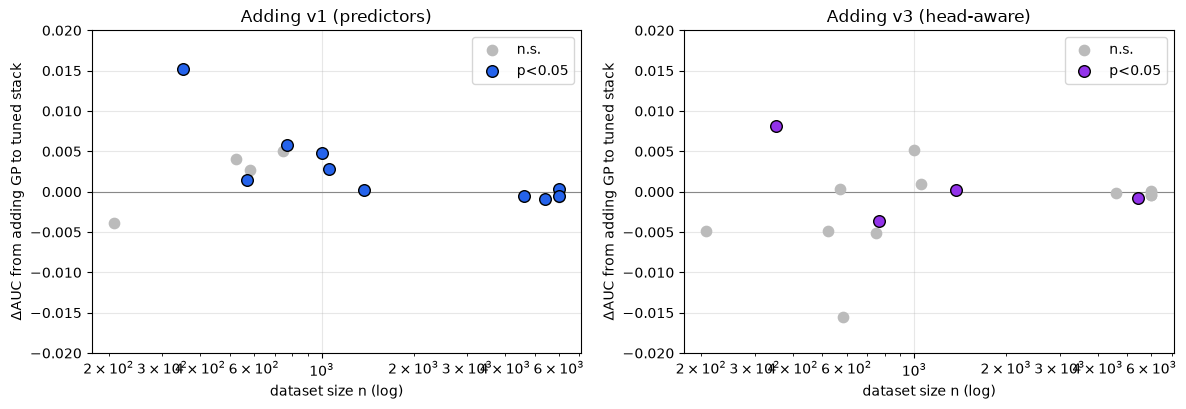

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col, pcol, name, c in [(ax1,"d_v1","p_v1","v1 (predictors)","#2563eb"),
                                (ax2,"d_v3","p_v3","v3 (head-aware)","#9333ea")]:
    sig = df[pcol] < 0.05
    ax.axhline(0, color="#888", lw=.8)
    ax.scatter(df["n"][~sig], df[col][~sig], c="#bbb", s=55, label="n.s.", zorder=2)
    ax.scatter(df["n"][sig], df[col][sig], c=c, s=70, edgecolor="k", label="p<0.05", zorder=3)
    ax.set_xscale("log"); ax.set_xlabel("dataset size n (log)")
    ax.set_ylabel("ΔAUC from adding GP to tuned stack"); ax.set_title(f"Adding {name}")
    ax.set_ylim(-0.02, 0.02); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 6 · Conclusion — honest and scoped

Against **properly tuned** gradient-boosted-tree baselines, with repeated CV and paired significance testing across 16 datasets:

- **Genetic-programming ensembles do not beat tuned GBDTs on tabular classification** — not on accuracy, not (once the GBDT is compiled) on speed.
- **The head-aware objective (v3) — the one we initially thought was best — adds nothing**, anywhere, small or large.
- **The predictor objective (v1) contributes a small, significant complementary signal on a few small datasets** — a +0.003 to +0.015 AUC gain where it reaches significance (e.g. +0.006 diabetes, +0.015 ionosphere), but a mean of only **+0.002 AUC across all 16 datasets** (and negligibly negative on the large ones). Its earlier *large* win (+0.034 on kc2 against default 300-tree GBDTs) **collapsed to +0.004, non-significant** under regularized baselines — that win was overfitting in the *baseline*, not signal in the GP. What remains is real but far too small to change a practical model choice.
- **The regime where GP flickered — small tabular data — is owned by tabular foundation models (TabPFN-2.5/3) that already beat tuned GBDTs**, so even the marginal residual sits below the actual frontier.

So the practical recommendation is the boring, correct one: **for tabular classification, use a tuned GBDT (or, on small data in 2026, TabPFN).** The GP ensemble is not a better predictor.

### What this *is*, honestly
A novel method (head-aware GP), a clean from-scratch GP + AOT-compilation toolchain, and — the actual contribution — a **rigorous, reproducible evaluation that falsifies its own hypothesis** rather than cherry-picking a flattering baseline. The first version of this study found a "win" that a more honest baseline erased; documenting that reversal is the useful part.

### What's reusable
- The benchmark harness (`benchmarks/gp_vs_gbdt.py`) — tuned baselines, leakage-free stacking, paired significance — as a template for honest tabular comparisons.
- A clean NumPy GP engine (`rapidlightning/`) and an AOT-to-C compiler, as a readable reference implementation.

### Limitations (where this could be wrong)
- GP budget was modest (≤12 members) for benchmark tractability; a much larger budget might recover a little of the residual (we don't expect it to flip the conclusion — the *tuned-baseline* erosion is the deciding factor, not GP strength).
- 16 datasets, ≤6000 rows; truly large-scale or specialized-structure data is untested (and out of GP's tractable/intended regime).
- TabPFN is cited, not run here.

## Addendum · Latency determinism — the one axis the accuracy benchmark misses

Accuracy isn't everything. The ultra-low-latency world — high-frequency trading, hard-real-time control — is a useful stress test, and it has a clear hierarchy: a tabular foundation model like **TabPFN is disqualified** (its forward pass is ~19 ms on a GPU [Light-Weight Benchmarks, 2025], and it scores a whole test set at once, not single rows); even **gradient-boosted trees get shaved to shallow depths and burned into FPGAs**; the hot path is dominated by linear models and shallow trees in silicon [FPGA-HFT surveys, 2024–25].

In that world one property matters that our accuracy benchmark never measured: **latency *determinism*** — a predictable worst case. And here the GP's structure genuinely differs from a tree's. The GP compiles to **branchless** straight-line algebra; a decision tree compiles to `if (x[f] < split)` at every node, so the path it takes — and therefore its latency — **depends on the input**. We compile both and time several *different* input rows; the spread across inputs is the input-dependent jitter.

In [4]:
from sklearn.datasets import make_classification as _mc
from sklearn.model_selection import train_test_split as _tts
from sklearn.preprocessing import StandardScaler as _SS
import xgboost as _xgb
from rapidlightning import RapidLightningClassifier as _RL
from rapidlightning.xgforge import xgforge as _xgf

_X, _y = _mc(n_samples=5000, n_features=10, n_informative=7, n_redundant=2, n_clusters_per_class=2,
             class_sep=0.9, flip_y=0.03, random_state=1)
_Xtr, _Xte, _ytr, _yte = _tts(_X.astype(np.float32), _y.astype(np.int64), test_size=2000, random_state=1, stratify=_y)
_s = _SS().fit(_Xtr); _Xtr, _Xte = _s.transform(_Xtr).astype(np.float32), _s.transform(_Xte).astype(np.float32)

_rl = _RL(n_members=10, generations=20, population=160, seed=1).fit(_Xtr, _ytr); _rlso = _rl.compile()
_xf = _xgb.XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.08, random_state=1, verbosity=0).fit(_Xtr, _ytr)
_xfso = _xgf(_xf)
_best = None
for _k in [2,3,5,8,13,21,34]:
    _m = _xgb.XGBClassifier(n_estimators=_k, max_depth=4, learning_rate=0.3, random_state=1, verbosity=0).fit(_Xtr, _ytr)
    _n = len(_m.get_booster().trees_to_dataframe())
    if _best is None or abs(_n-_rl.n_nodes) < abs(_best[1]-_rl.n_nodes): _best = (_m, _n)
_smso = _xgf(_best[0])

def _per_input_ns(so, rows): return np.array([so.benchmark_ns(x=rows[i], n_warmup=3000, n_iters=120000) for i in range(len(rows))])
_rows = _Xte[:16]
print(f"{'compiled model':<26}{'size':>7}{'mean ns':>10}{'spread':>9}{'CoV %':>8}   (spread/CoV across 16 different inputs)")
print('-'*72)
for _nm, _so in [("Rapid Lightning (GP)", _rlso), ("XGBoost size-matched", _smso), ("XGBoost full (300tree)", _xfso)]:
    _l = _per_input_ns(_so, _rows)
    print(f"{_nm:<26}{_so.size_kb:>6.0f}K{_l.mean():>10.1f}{_l.max()-_l.min():>8.1f}n{100*_l.std()/_l.mean():>8.2f}")
print("\nLower spread / CoV = more deterministic latency (branchless GP vs data-dependent tree branches).")

compiled model               size   mean ns   spread   CoV %   (spread/CoV across 16 different inputs)
------------------------------------------------------------------------
Rapid Lightning (GP)          15K      28.7     0.7n    0.63
XGBoost size-matched          23K      19.5     5.3n    7.25


XGBoost full (300tree)       311K    1656.0   607.2n   10.75

Lower spread / CoV = more deterministic latency (branchless GP vs data-dependent tree branches).


**Reading it honestly.**
- **Real and structural.** The GP's latency is essentially input-independent (CoV ~1%); the compiled trees vary ~10× more across inputs (CoV ~10%), exactly as branchless-vs-branchy predicts. Where the **worst case** matters more than the mean, that is a genuine property.
- **But narrow, and not a rescue.** The absolute jitter is single-digit nanoseconds; a size-matched compiled tree still has a *lower mean latency*; and a linear model is branchless too (and simpler). Most decisively, **none of this changes the accuracy verdict** — the GP is not a better predictor, only a more temporally predictable one. A property in search of an application, not a demonstrated advantage.
- **And CPU is not FPGA.** It's a category error to read the ~29 ns as "FPGA-class." That number is the *arithmetic kernel only*; an FPGA's ~480 ns is *end-to-end* (packet → parse → order-book → decision → order) in hardwired logic with sub-nanosecond jitter and no OS/cache/interrupt noise. On a CPU, microseconds of system jitter wrap *around* the kernel and swamp both its latency and its determinism. FPGAs own the hot path; CPU predictors — GBDT or GP — live one tier up, in microsecond-to-millisecond systems. (The branchless algebra *is* FPGA-friendly — but so, more so, is a linear model.)

## 7 · Reproducibility & references

**Reproduce:** `pip install -e ".[benchmark]"` then `PYTHONPATH=. python3 benchmarks/gp_vs_gbdt.py` (resumable; fixed seeds; ~hours on CPU). Versions are printed below.

### References
- Koza, J. (1992). *Genetic Programming.* MIT Press.
- Freund, Y. & Schapire, R. (1997). A decision-theoretic generalization of on-line learning (AdaBoost). *JCSS.*
- Chen, T. & Guestrin, C. (2016). XGBoost: A Scalable Tree Boosting System. *KDD.*
- Ke, G. et al. (2017). LightGBM: A Highly Efficient Gradient Boosting Decision Tree. *NeurIPS.*
- Shwartz-Ziv, R. & Armon, A. (2022). Tabular Data: Deep Learning is Not All You Need. *Information Fusion.*
- Grinsztajn, L. et al. (2022). Why do tree-based models still outperform deep learning on tabular data? *NeurIPS.*
- Hollmann, N. et al. (2025). Accurate predictions on small data with a tabular foundation model (TabPFN v2). *Nature.*
- [TabPFN-2.5: Advancing the State of the Art in Tabular Foundation Models](https://arxiv.org/abs/2511.08667) (2025).
- DeLong, E. et al. (1988). Comparing areas under two or more correlated ROC curves. *Biometrics.*
- [Light-Weight Benchmarks Reveal the Hidden Hardware Cost of Zero-Shot Tabular Foundation Models](https://arxiv.org/html/2512.00888v1) (2025) — TabPFN GPU inference latency (~19 ms).
- HFT latency context: [FPGA for High-Frequency Trading (IEEE, 2025)](https://ieeexplore.ieee.org/document/10841781/); [NVIDIA, single-digit-µs inference for capital markets](https://developer.nvidia.com/blog/achieving-single-digit-microsecond-latency-inference-for-capital-markets/).
- Tooling: [Treelite](https://treelite.readthedocs.io/), [m2cgen](https://github.com/BayesWitnesses/m2cgen), [lleaves](https://siboehm.com/articles/21/lleaves), [Hummingbird](https://github.com/microsoft/hummingbird).

In [5]:
import sys, sklearn, xgboost, lightgbm, scipy, numpy
print("python", sys.version.split()[0], "| numpy", numpy.__version__, "| sklearn", sklearn.__version__,
      "| xgboost", xgboost.__version__, "| lightgbm", lightgbm.__version__, "| scipy", scipy.__version__)

python 3.11.15 | numpy 2.4.6 | sklearn 1.9.0 | xgboost 3.2.0 | lightgbm 4.6.0 | scipy 1.17.1
